# Shelter Animal Outcomes — Klasyfikacja

**Cel:** Przewidywanie wyniku pobytu zwierzęcia w schronisku (adopcja, transfer, powrót do właściciela, eutanazja, śmierć).

**Zbiór danych:** Austin Animal Center - Kaggle Competition (train.csv)

**Autor:** Natalia Jona, 347793

## 0. Importy i ustawienia

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.model_selection import GridSearchCV

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Wczytanie danych

In [36]:
df_raw = pd.read_csv("train.csv")

print(f"Kształt zbioru: {df_raw.shape}")
print(f"\nKolumny i typy:")
print(df_raw.dtypes)
print(f"\nPierwsze 5 wierszy:")
df_raw.head()

Kształt zbioru: (26729, 10)

Kolumny i typy:
AnimalID          object
Name              object
DateTime          object
OutcomeType       object
OutcomeSubtype    object
AnimalType        object
SexuponOutcome    object
AgeuponOutcome    object
Breed             object
Color             object
dtype: object

Pierwsze 5 wierszy:


,AnimalID,Name,DateTime,OutcomeType,OutcomeSubtype,AnimalType,SexuponOutcome,AgeuponOutcome,Breed,Color
0,A671945,Hambone,2014-02-12 18:22:00,Return_to_owner,NaN,Dog,Neutered Male,1 year,Shetland Sheepdog Mix,Brown/White
1,A656520,Emily,2013-10-13 12:44:00,Euthanasia,Suffering,Cat,Spayed Female,1 year,Domestic Shorthair Mix,Cream Tabby
2,A686464,Pearce,2015-01-31 12:28:00,Adoption,Foster,Dog,Neutered Male,2 years,Pit Bull Mix,Blue/White
3,A683430,NaN,2014-07-11 19:09:00,Transfer,Partner,Cat,Intact Male,3 weeks,Domestic Shorthair Mix,Blue Cream
4,A667013,NaN,2013-11-15 12:52:00,Transfer,Partner,Dog,Neutered Male,2 years,Lhasa Apso/Miniature Poodle,Tan


## 2. Analiza eksploracyjna (EDA)

### 2.1 Wstępna analiza statystyczna

In [37]:
print("Braki danych:")
missing = df_raw.isna().sum()
print(missing[missing > 0])
print(f"\nŁączna liczba braków: {df_raw.isna().sum().sum()}")
print(f"Procent wierszy z co najmniej 1 brakiem: {(df_raw.isna().any(axis=1).mean()*100):.1f}%")

Braki danych:
Name               7691
OutcomeSubtype    13612
SexuponOutcome        1
AgeuponOutcome       18
dtype: int64

Łączna liczba braków: 21322
Procent wierszy z co najmniej 1 brakiem: 73.9%


### 2.2 Zmienna docelowa — OutcomeType

Rozkład klas:
  Adoption              10769  (40.3%)
  Transfer               9422  (35.3%)
  Return_to_owner        4786  (17.9%)
  Euthanasia             1555  (5.8%)
  Died                    197  (0.7%)


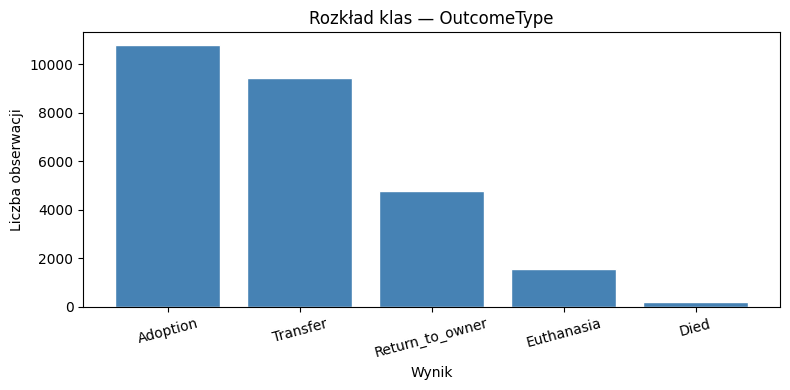


Zbiór jest NIEZBALANSOWANY:
  Klasa dominująca (Adoption):  40.3%
  Klasa rzadka     (Died):       0.7%


In [38]:
counts = df_raw['OutcomeType'].value_counts()
pcts   = df_raw['OutcomeType'].value_counts(normalize=True) * 100

print("Rozkład klas:")
for cls, cnt, pct in zip(counts.index, counts.values, pcts.values):
    print(f"  {cls:<20} {cnt:>6}  ({pct:.1f}%)")

# Wykres
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.index, counts.values, color='steelblue', edgecolor='white')
ax.set_title('Rozkład klas — OutcomeType')
ax.set_xlabel('Wynik')
ax.set_ylabel('Liczba obserwacji')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Dane są niezbalansowane - klasa Died ma tylko ~0.7% obserwacji
print(f"\nZbiór jest NIEZBALANSOWANY:")
print(f"  Klasa dominująca (Adoption):  {pcts['Adoption']:.1f}%")
print(f"  Klasa rzadka     (Died):       {pcts['Died']:.1f}%")

### 2.3 Rozkład według typu zwierzęcia

Procent wyników dla psów i kotów:
OutcomeType  Adoption  Died  Euthanasia  Return_to_owner  Transfer
AnimalType                                                        
Cat              38.4   1.3         6.4              4.5      49.4
Dog              41.7   0.3         5.4             27.5      25.1


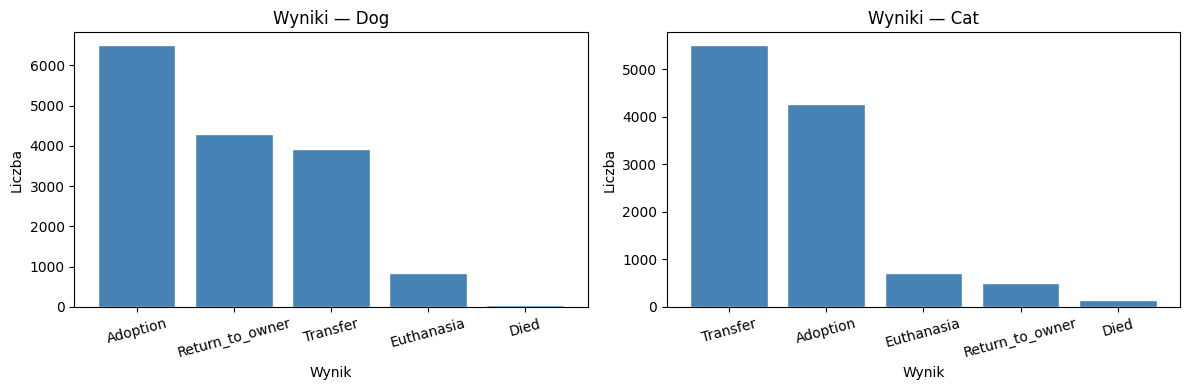

In [39]:
ct = pd.crosstab(df_raw['AnimalType'], df_raw['OutcomeType'], normalize='index') * 100
print("Procent wyników dla psów i kotów:")
print(ct.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, animal in zip(axes, ['Dog', 'Cat']):
    sub = df_raw[df_raw['AnimalType'] == animal]['OutcomeType'].value_counts()
    ax.bar(sub.index, sub.values, color='steelblue', edgecolor='white')
    ax.set_title(f'Wyniki — {animal}')
    ax.set_xlabel('Wynik')
    ax.set_ylabel('Liczba')
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=15)
plt.tight_layout()
plt.show()

### 2.4 Rozkład wieku zwierząt

Statystyki wieku (w dniach):
count    26711.0
mean       794.1
std       1082.8
min          0.0
25%         60.0
50%        365.0
75%       1095.0
max       7300.0
Name: AgeuponOutcome, dtype: float64


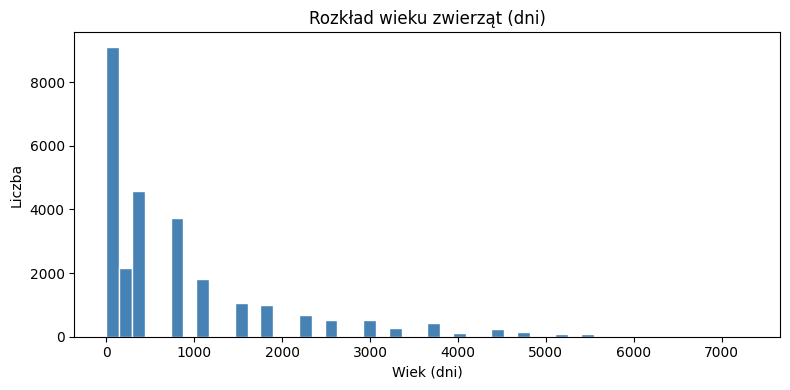

In [40]:
def age_to_days(age_str):
    """Konwertuje string 'X unit' na liczbę dni."""
    if pd.isna(age_str):
        return np.nan
    parts = str(age_str).strip().split()
    if len(parts) != 2:
        return np.nan
    val = int(parts[0])
    unit = parts[1].lower().rstrip('s')  # usuwa plural 's'
    mapping = {'day': 1, 'week': 7, 'month': 30, 'year': 365}
    return val * mapping.get(unit, np.nan)

age_days = df_raw['AgeuponOutcome'].apply(age_to_days)
print("Statystyki wieku (w dniach):")
print(age_days.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(age_days.dropna(), bins=50, color='steelblue', edgecolor='white')
ax.set_title('Rozkład wieku zwierząt (dni)')
ax.set_xlabel('Wiek (dni)')
ax.set_ylabel('Liczba')
plt.tight_layout()
plt.show()

### 2.5 Rozkład wyników w czasie

Liczba wyników wg roku:
OutcomeType  Adoption  Died  Euthanasia  Return_to_owner  Transfer
rok                                                               
2013             1128    16         183              434       941
2014             4358    69         724             1880      4148
2015             4620   104         610             2167      3980
2016              663     8          38              305       353


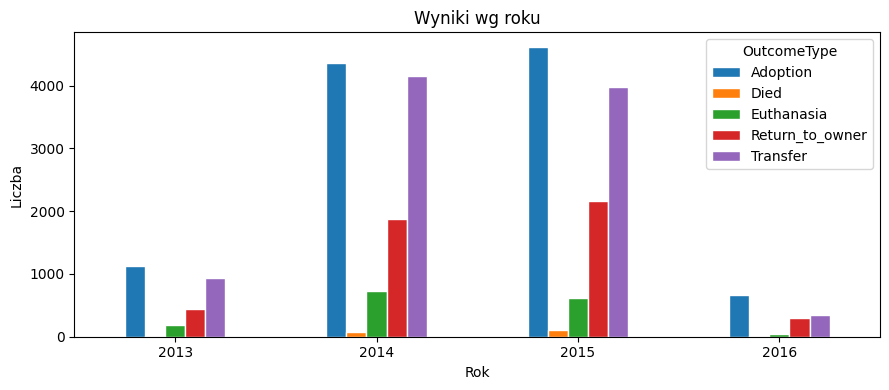

In [41]:
df_raw['DateTime_dt'] = pd.to_datetime(df_raw['DateTime'])
df_raw['rok'] = df_raw['DateTime_dt'].dt.year

rok_outcome = pd.crosstab(df_raw['rok'], df_raw['OutcomeType'])
print("Liczba wyników wg roku:")
print(rok_outcome)

rok_outcome.plot(kind='bar', figsize=(9, 4), edgecolor='white')
plt.title('Wyniki wg roku')
plt.xlabel('Rok')
plt.ylabel('Liczba')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 2.6 Wpływ posiadania imienia

Wyniki wg posiadania imienia (%):
OutcomeType  Adoption  Died  Euthanasia  Return_to_owner  Transfer
ma_imie                                                           
0                21.8   1.6        10.6              2.0      64.0
1                47.8   0.4         3.9             24.3      23.6


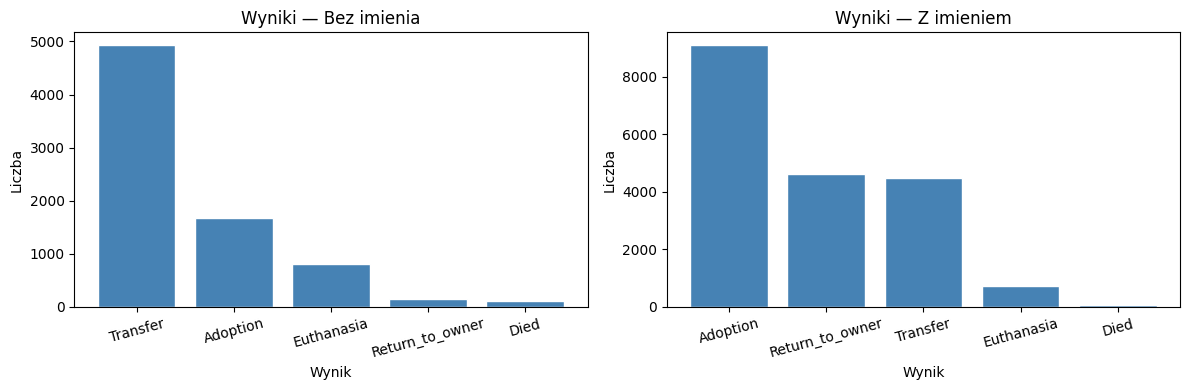

In [42]:
df_raw['ma_imie'] = df_raw['Name'].notna().astype(int)
ct_imie = pd.crosstab(df_raw['ma_imie'], df_raw['OutcomeType'], normalize='index') * 100
print("Wyniki wg posiadania imienia (%):")
print(ct_imie.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, val, label in zip(axes, [0, 1], ['Bez imienia', 'Z imieniem']):
    sub = df_raw[df_raw['ma_imie'] == val]['OutcomeType'].value_counts()
    ax.bar(sub.index, sub.values, color='steelblue', edgecolor='white')
    ax.set_title(f'Wyniki — {label}')
    ax.set_xlabel('Wynik')
    ax.set_ylabel('Liczba')
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=15)
plt.tight_layout()
plt.show()

### 2.7 Wartości odstające w wieku

Q1=60 dni, Q3=1095 dni, IQR=1035 dni
Wartości odstające wg IQR: 2023 (7.6%)


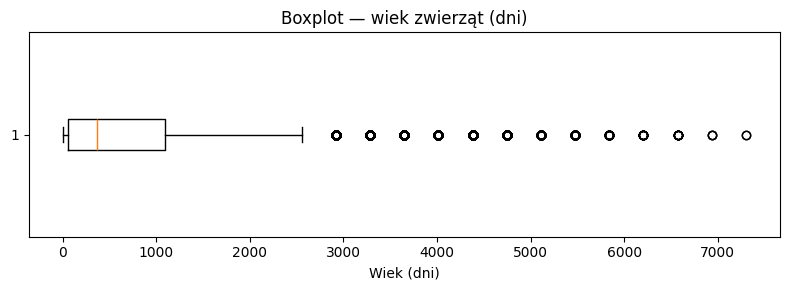


Zwierząt starszych niż 10 lat: 753


In [43]:
q1 = age_days.quantile(0.25)
q3 = age_days.quantile(0.75)
iqr = q3 - q1
outliers = ((age_days < q1 - 1.5*iqr) | (age_days > q3 + 1.5*iqr)).sum()
print(f"Q1={q1:.0f} dni, Q3={q3:.0f} dni, IQR={iqr:.0f} dni")
print(f"Wartości odstające wg IQR: {outliers} ({outliers/len(age_days)*100:.1f}%)")

fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot(age_days.dropna(), vert=False)
ax.set_title('Boxplot — wiek zwierząt (dni)')
ax.set_xlabel('Wiek (dni)')
plt.tight_layout()
plt.show()

# Wiek > 10 lat (3650 dni) - seniorzy
print(f"\nZwierząt starszych niż 10 lat: {(age_days > 3650).sum()}")

## 3. Preprocessing i inżynieria cech

In [44]:
df = df_raw.copy()

# 1) Usuwa kolumny nieprzydatne lub powodujące leakage
df = df.drop(columns=['AnimalID', 'OutcomeSubtype', 'DateTime_dt', 'rok'])
# OutcomeSubtype = subtyp wyniku -> data leakage (zależy od OutcomeType)
# AnimalID = identyfikator bez wartości predykcyjnej

# 2) Zmienna docelowa
y = df['OutcomeType']
df = df.drop(columns=['OutcomeType'])

print("Kolumny po usunięciu zbędnych:")
print(df.columns.tolist())

Kolumny po usunięciu zbędnych:
['Name', 'DateTime', 'AnimalType', 'SexuponOutcome', 'AgeuponOutcome', 'Breed', 'Color', 'ma_imie']


In [45]:
# 3) Inżynieria cech

# Wiek w dniach
df['wiek_dni'] = df['AgeuponOutcome'].apply(age_to_days)

# Flaga: czy zwierzę ma imię
df['ma_imie'] = df['Name'].notna().astype(int)

# Płeć i status kastracji - rozbicie SexuponOutcome
def parse_sex(s):
    if pd.isna(s) or s == 'Unknown':
        return np.nan, np.nan
    parts = s.strip().split()
    if len(parts) == 2:
        kastracja = 1 if parts[0] in ['Neutered', 'Spayed'] else 0
        plec = parts[1]  # Male / Female
        return kastracja, plec
    return np.nan, np.nan

sex_parsed = df['SexuponOutcome'].apply(lambda x: pd.Series(parse_sex(x), index=['kastracja', 'plec']))
df['kastracja'] = sex_parsed['kastracja']
df['plec']      = sex_parsed['plec']

# Flaga: rasa mieszana
df['rasa_mieszana'] = df['Breed'].str.contains('Mix|/', na=False).astype(int)

# Flaga: wiele kolorów
df['wiele_kolorow'] = df['Color'].str.contains('/', na=False).astype(int)

# Cechy czasowe z DateTime
df['DateTime_dt'] = pd.to_datetime(df['DateTime'])
df['godzina']      = df['DateTime_dt'].dt.hour
df['dzien_tyg']    = df['DateTime_dt'].dt.dayofweek  # 0=pn, 6=nd
df['miesiac']      = df['DateTime_dt'].dt.month
df['rok']          = df['DateTime_dt'].dt.year

# Wiek kategoryczny (senior = > 7 lat = >2555 dni)
df['senior'] = (df['wiek_dni'] > 2555).astype(int)

# Usuwa surowe kolumny po ekstrakcji
df = df.drop(columns=['Name', 'AgeuponOutcome', 'SexuponOutcome', 'DateTime', 'DateTime_dt'])

print("Kolumny po inżynierii cech:")
print(df.dtypes)
print(f"\nKształt: {df.shape}")

Kolumny po inżynierii cech:
AnimalType        object
Breed             object
Color             object
ma_imie            int64
wiek_dni         float64
kastracja        float64
plec              object
rasa_mieszana      int64
wiele_kolorow      int64
godzina            int32
dzien_tyg          int32
miesiac            int32
rok                int32
senior             int64
dtype: object

Kształt: (26729, 14)


In [46]:
# Sprawdzenie braków po inżynierii
print("Braki po inżynierii cech:")
print(df.isna().sum()[df.isna().sum() > 0])

Braki po inżynierii cech:
wiek_dni       18
kastracja    1094
plec         1094
dtype: int64


In [47]:
# 4) Definicja cech numerycznych i kategorycznych
numeric_features     = ['wiek_dni', 'godzina', 'dzien_tyg', 'miesiac', 'rok']
binary_features      = ['ma_imie', 'kastracja', 'rasa_mieszana', 'wiele_kolorow', 'senior']
categorical_features = ['AnimalType', 'plec', 'Breed', 'Color']

# Weryfikacja że wszystkie kolumny są uwzględnione
all_feat = numeric_features + binary_features + categorical_features
print("Cechy numeryczne:   ", numeric_features)
print("Cechy binarne:      ", binary_features)
print("Cechy kategoryczne: ", categorical_features)
print(f"\nLączna liczba cech wejściowych: {len(all_feat)}")

Cechy numeryczne:    ['wiek_dni', 'godzina', 'dzien_tyg', 'miesiac', 'rok']
Cechy binarne:       ['ma_imie', 'kastracja', 'rasa_mieszana', 'wiele_kolorow', 'senior']
Cechy kategoryczne:  ['AnimalType', 'plec', 'Breed', 'Color']

Lączna liczba cech wejściowych: 14


In [48]:
# 5) Podział train/test (stratyfikowany)
X = df[all_feat]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Zbiór treningowy: {X_train.shape}")
print(f"Zbiór testowy:    {X_test.shape}")
print(f"\nRozkład klas w train:")
print((y_train.value_counts(normalize=True)*100).round(1))
print(f"\nRozkład klas w test:")
print((y_test.value_counts(normalize=True)*100).round(1))

Zbiór treningowy: (21383, 14)
Zbiór testowy:    (5346, 14)

Rozkład klas w train:
OutcomeType
Adoption           40.3
Transfer           35.2
Return_to_owner    17.9
Euthanasia          5.8
Died                0.7
Name: proportion, dtype: float64

Rozkład klas w test:
OutcomeType
Adoption           40.3
Transfer           35.3
Return_to_owner    17.9
Euthanasia          5.8
Died                0.7
Name: proportion, dtype: float64


In [49]:
# 6) Preprocessor - Pipeline

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

binary_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer,     numeric_features),
    ('bin', binary_transformer,      binary_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessor zdefiniowany.")
print("Schemat przetwarzania:")
print("  - Numeryczne:   imputacja medianą + StandardScaler")
print("  - Binarne:      imputacja modą (już 0/1, bez skalowania)")
print("  - Kategoryczne: imputacja stałą 'unknown' + OrdinalEncoder")

Preprocessor zdefiniowany.
Schemat przetwarzania:
  - Numeryczne:   imputacja medianą + StandardScaler
  - Binarne:      imputacja modą (już 0/1, bez skalowania)
  - Kategoryczne: imputacja stałą 'unknown' + OrdinalEncoder


## 4. Modele klasyfikacyjne

### 4.1 Baseline — DummyClassifier

In [50]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

acc_baseline = accuracy_score(y_test, y_pred_baseline)
bal_baseline = balanced_accuracy_score(y_test, y_pred_baseline)

print(f"Baseline accuracy:          {acc_baseline:.4f}")
print(f"Baseline balanced accuracy: {bal_baseline:.4f}")
print("\nModel bazowy zawsze przewiduje najczęstszą klasę (Adoption).")
print("Wynik ten stanowi minimalny poziom skuteczności, który muszą pobić właściwe modele.")

Baseline accuracy:          0.4029
Baseline balanced accuracy: 0.2000

Model bazowy zawsze przewiduje najczęstszą klasę (Adoption).
Wynik ten stanowi minimalny poziom skuteczności, który muszą pobić właściwe modele.


### 4.2 Model 1 — Logistic Regression

In [51]:
pipe_lr = Pipeline([
    ('preprocessing', preprocessor),
    ('model', LogisticRegression(max_iter=10000, random_state=RANDOM_STATE, solver='saga', tol=0.01))
])

pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)

acc_lr = accuracy_score(y_test, y_pred_lr)
bal_lr = balanced_accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression accuracy:          {acc_lr:.4f}")
print(f"Logistic Regression balanced accuracy: {bal_lr:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Logistic Regression accuracy:          0.5627
Logistic Regression balanced accuracy: 0.3101

Classification Report:
                 precision    recall  f1-score   support

       Adoption       0.54      0.84      0.66      2154
           Died       0.00      0.00      0.00        39
     Euthanasia       0.00      0.00      0.00       311
Return_to_owner       0.45      0.15      0.23       957
       Transfer       0.62      0.55      0.59      1885

       accuracy                           0.56      5346
      macro avg       0.32      0.31      0.30      5346
   weighted avg       0.52      0.56      0.51      5346



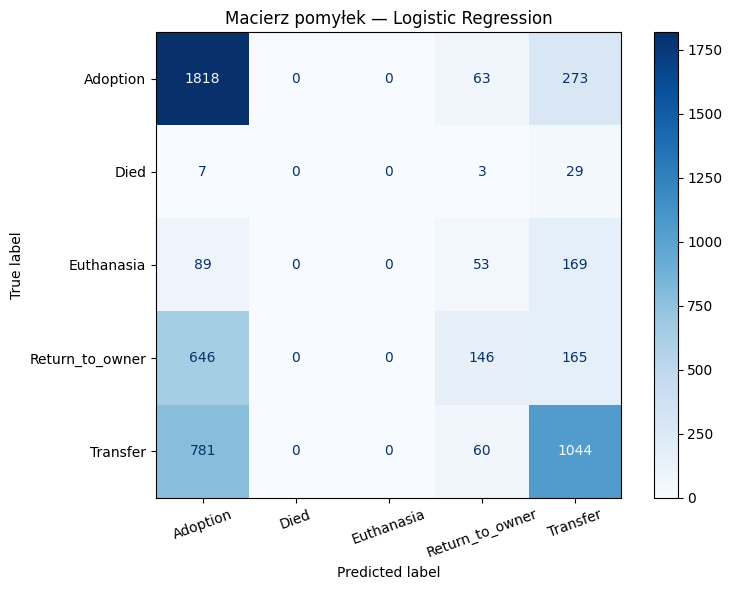

In [52]:
# Macierz pomyłek - Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=pipe_lr.classes_)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=pipe_lr.classes_)
fig, ax = plt.subplots(figsize=(8, 6))
disp_lr.plot(ax=ax, colorbar=True, cmap='Blues')
ax.set_title('Macierz pomyłek — Logistic Regression')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 4.3 Model 2 — Random Forest

In [53]:
pipe_rf = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))
])

pipe_rf.fit(X_train, y_train)
y_pred_rf = pipe_rf.predict(X_test)

acc_rf = accuracy_score(y_test, y_pred_rf)
bal_rf = balanced_accuracy_score(y_test, y_pred_rf)

print(f"Random Forest accuracy:          {acc_rf:.4f}")
print(f"Random Forest balanced accuracy: {bal_rf:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Random Forest accuracy:          0.6852
Random Forest balanced accuracy: 0.4464

Classification Report:
                 precision    recall  f1-score   support

       Adoption       0.71      0.83      0.76      2154
           Died       0.00      0.00      0.00        39
     Euthanasia       0.61      0.21      0.31       311
Return_to_owner       0.50      0.47      0.48       957
       Transfer       0.75      0.73      0.74      1885

       accuracy                           0.69      5346
      macro avg       0.51      0.45      0.46      5346
   weighted avg       0.67      0.69      0.67      5346



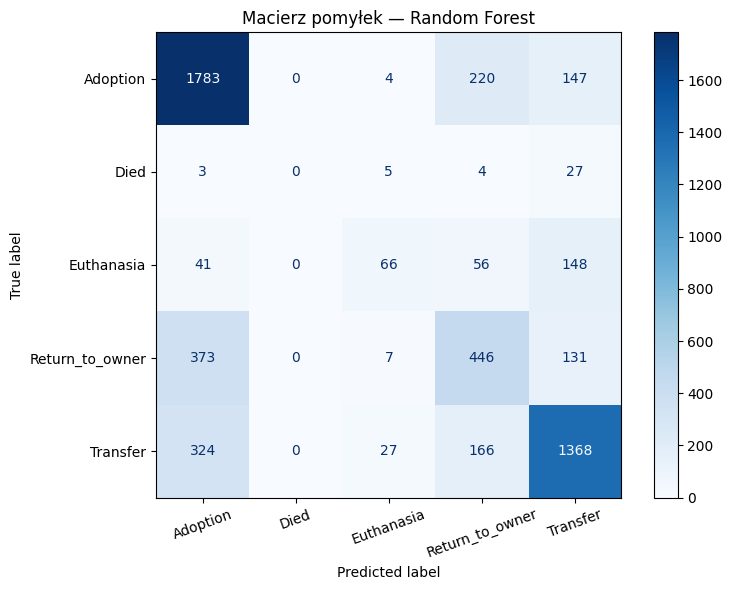

In [54]:
# Macierz pomyłek - Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=pipe_rf.classes_)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=pipe_rf.classes_)
fig, ax = plt.subplots(figsize=(8, 6))
disp_rf.plot(ax=ax, colorbar=True, cmap='Blues')
ax.set_title('Macierz pomyłek — Random Forest')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 4.4 Model 3 — k-NN

In [55]:
pipe_knn = Pipeline([
    ('preprocessing', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

pipe_knn.fit(X_train, y_train)
y_pred_knn = pipe_knn.predict(X_test)

acc_knn = accuracy_score(y_test, y_pred_knn)
bal_knn = balanced_accuracy_score(y_test, y_pred_knn)

print(f"k-NN accuracy:          {acc_knn:.4f}")
print(f"k-NN balanced accuracy: {bal_knn:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

k-NN accuracy:          0.5436
k-NN balanced accuracy: 0.3280

Classification Report:
                 precision    recall  f1-score   support

       Adoption       0.55      0.75      0.63      2154
           Died       0.00      0.00      0.00        39
     Euthanasia       0.20      0.07      0.10       311
Return_to_owner       0.36      0.30      0.33       957
       Transfer       0.65      0.52      0.58      1885

       accuracy                           0.54      5346
      macro avg       0.35      0.33      0.33      5346
   weighted avg       0.53      0.54      0.53      5346



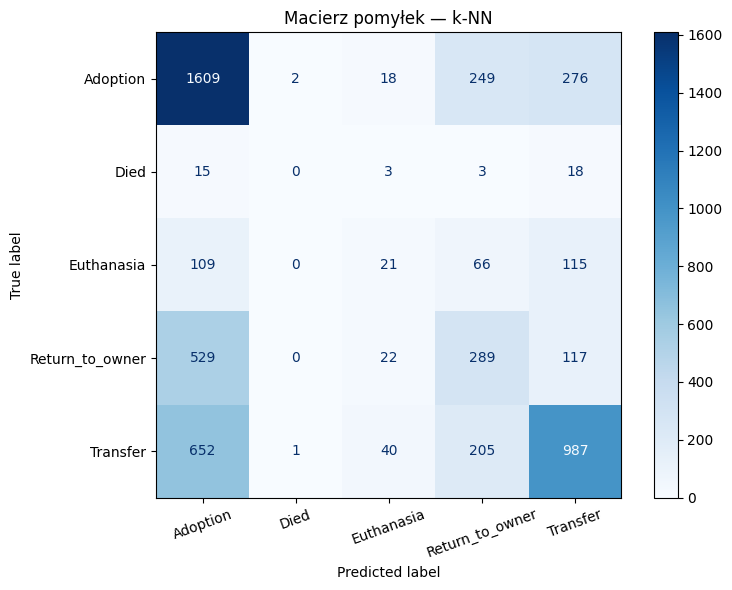

In [56]:
# Macierz pomyłek - kNN
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=pipe_knn.classes_)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=pipe_knn.classes_)
fig, ax = plt.subplots(figsize=(8, 6))
disp_knn.plot(ax=ax, colorbar=True, cmap='Blues')
ax.set_title('Macierz pomyłek — k-NN')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 4.5 Porównanie modeli przed strojeniem

              Model  Accuracy  Balanced Accuracy
      Random Forest    0.6852             0.4464
Logistic Regression    0.5627             0.3101
               k-NN    0.5436             0.3280
           Baseline    0.4029             0.2000


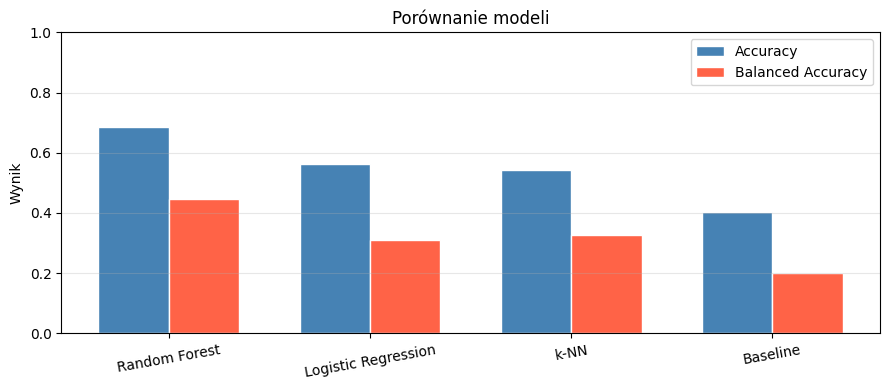

In [57]:
wyniki = {
    'Model':            ['Baseline', 'Logistic Regression', 'Random Forest', 'k-NN'],
    'Accuracy':         [acc_baseline, acc_lr, acc_rf, acc_knn],
    'Balanced Accuracy':[bal_baseline, bal_lr, bal_rf, bal_knn],
}

df_wyniki = pd.DataFrame(wyniki)
df_wyniki = df_wyniki.sort_values('Accuracy', ascending=False).reset_index(drop=True)
print(df_wyniki.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(df_wyniki))
w = 0.35
ax.bar(x - w/2, df_wyniki['Accuracy'],          w, label='Accuracy',          color='steelblue', edgecolor='white')
ax.bar(x + w/2, df_wyniki['Balanced Accuracy'],  w, label='Balanced Accuracy', color='tomato',    edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(df_wyniki['Model'], rotation=10)
ax.set_ylabel('Wynik')
ax.set_title('Porównanie modeli')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 5. Strojenie hiperparametrów

### 5.1 Logistic Regression

In [58]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grid_lr = {
    'model__C':       [0.01, 0.1, 1, 10],
    'model__penalty': ['l2']
}

grid_lr = GridSearchCV(
    pipe_lr, param_grid_lr,
    cv=cv, scoring='accuracy',
    n_jobs=-1, refit=True
)
grid_lr.fit(X_train, y_train)

print("Najlepsze parametry (LR):", grid_lr.best_params_)
print(f"Najlepszy wynik CV:       {grid_lr.best_score_:.4f}")

acc_lr_tuned = accuracy_score(y_test, grid_lr.predict(X_test))
bal_lr_tuned = balanced_accuracy_score(y_test, grid_lr.predict(X_test))
print(f"Accuracy na teście:       {acc_lr_tuned:.4f}")
print(f"Balanced acc na teście:   {bal_lr_tuned:.4f}")

Najlepsze parametry (LR): {'model__C': 0.1, 'model__penalty': 'l2'}
Najlepszy wynik CV:       0.5630
Accuracy na teście:       0.5627
Balanced acc na teście:   0.3101


### 5.2 Random Forest

In [59]:
param_grid_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth':    [None, 10, 20],
    'model__min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(
    pipe_rf, param_grid_rf,
    cv=cv, scoring='accuracy',
    n_jobs=-1, refit=True
)
grid_rf.fit(X_train, y_train)

print("Najlepsze parametry (RF):", grid_rf.best_params_)
print(f"Najlepszy wynik CV:       {grid_rf.best_score_:.4f}")

acc_rf_tuned = accuracy_score(y_test, grid_rf.predict(X_test))
bal_rf_tuned = balanced_accuracy_score(y_test, grid_rf.predict(X_test))
print(f"Accuracy na teście:       {acc_rf_tuned:.4f}")
print(f"Balanced acc na teście:   {bal_rf_tuned:.4f}")

/Users/nataliajona/PyCharmMiscProject/.venv/lib/python3.9/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Najlepsze parametry (RF): {'model__max_depth': 20, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Najlepszy wynik CV:       0.6825
Accuracy na teście:       0.6906
Balanced acc na teście:   0.4458


### 5.3 k-NN

In [60]:
param_grid_knn = {
    'model__n_neighbors': [3, 5, 9, 15],
    'model__weights':     ['uniform', 'distance'],
    'model__p':           [1, 2]
}

grid_knn = GridSearchCV(
    pipe_knn, param_grid_knn,
    cv=cv, scoring='accuracy',
    n_jobs=-1, refit=True
)
grid_knn.fit(X_train, y_train)

print("Najlepsze parametry (kNN):", grid_knn.best_params_)
print(f"Najlepszy wynik CV:        {grid_knn.best_score_:.4f}")

acc_knn_tuned = accuracy_score(y_test, grid_knn.predict(X_test))
bal_knn_tuned = balanced_accuracy_score(y_test, grid_knn.predict(X_test))
print(f"Accuracy na teście:        {acc_knn_tuned:.4f}")
print(f"Balanced acc na teście:    {bal_knn_tuned:.4f}")

Najlepsze parametry (kNN): {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'distance'}
Najlepszy wynik CV:        0.5692
Accuracy na teście:        0.5812
Balanced acc na teście:    0.3455


### 5.4 Porównanie przed i po strojeniu

              Model  Przed strojeniem  Po strojeniu
Logistic Regression            0.5627        0.5627
      Random Forest            0.6852        0.6906
               k-NN            0.5436        0.5812


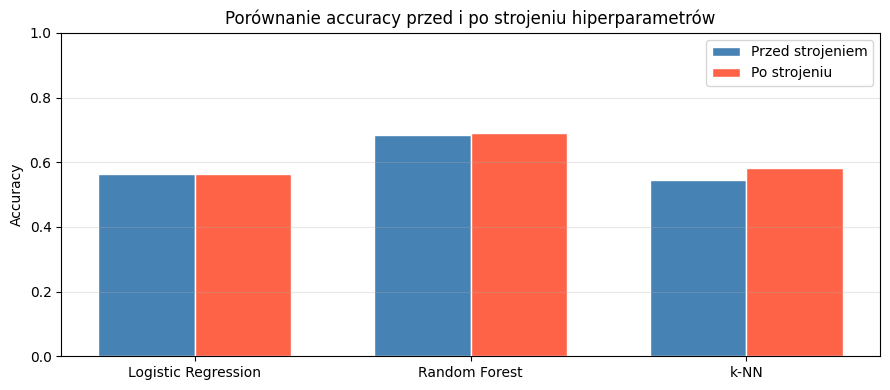

In [61]:
df_tuning = pd.DataFrame({
    'Model':             ['Logistic Regression', 'Random Forest', 'k-NN'],
    'Przed strojeniem':  [round(acc_lr, 4), round(acc_rf, 4), round(acc_knn, 4)],
    'Po strojeniu':      [round(acc_lr_tuned, 4), round(acc_rf_tuned, 4), round(acc_knn_tuned, 4)],
})
print(df_tuning.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(df_tuning))
w = 0.35
ax.bar(x - w/2, df_tuning['Przed strojeniem'], w, label='Przed strojeniem', color='steelblue', edgecolor='white')
ax.bar(x + w/2, df_tuning['Po strojeniu'],     w, label='Po strojeniu',     color='tomato',    edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(df_tuning['Model'])
ax.set_ylabel('Accuracy')
ax.set_title('Porównanie accuracy przed i po strojeniu hiperparametrów')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 6. Analiza najlepszego modelu — Random Forest

### 6.1 Analiza przeuczenia

In [62]:
best_rf = grid_rf.best_estimator_

train_score = best_rf.score(X_train, y_train)
test_score  = best_rf.score(X_test,  y_test)

print(f"Accuracy na zbiorze treningowym: {train_score:.4f}")
print(f"Accuracy na zbiorze testowym:    {test_score:.4f}")
print(f"Różnica (overfitting):           {train_score - test_score:.4f}")

if train_score - test_score > 0.05:
    print("\nModel wykazuje oznaki przeuczenia (różnica > 5%).")
else:
    print("\nModel jest dobrze uogólniony (różnica <= 5%).")

Accuracy na zbiorze treningowym: 0.9347
Accuracy na zbiorze testowym:    0.6906
Różnica (overfitting):           0.2441

Model wykazuje oznaki przeuczenia (różnica > 5%).


### 6.2 Analiza błędnych predykcji

In [63]:
y_pred_best = best_rf.predict(X_test)

# Ramka z błędami
X_test_copy = X_test.copy()
X_test_copy['prawdziwa_klasa']    = y_test.values
X_test_copy['przewidziana_klasa'] = y_pred_best

bledy = X_test_copy[X_test_copy['prawdziwa_klasa'] != X_test_copy['przewidziana_klasa']]
print(f"Liczba błędnych predykcji: {len(bledy)} / {len(X_test)} ({len(bledy)/len(X_test)*100:.1f}%)")
print("\nPrzykładowe błędne predykcje:")
print(bledy[['AnimalType', 'prawdziwa_klasa', 'przewidziana_klasa']].head(10).to_string())

# Jakie klasy są najczęściej mylone
print("\nNajczęściej mylone pary klas:")
print(bledy.groupby(['prawdziwa_klasa', 'przewidziana_klasa']).size()
      .sort_values(ascending=False).head(10))

Liczba błędnych predykcji: 1654 / 5346 (30.9%)

Przykładowe błędne predykcje:
      AnimalType  prawdziwa_klasa przewidziana_klasa
18757        Dog         Adoption    Return_to_owner
22557        Dog         Transfer           Adoption
13227        Dog  Return_to_owner           Adoption
18204        Cat       Euthanasia           Transfer
24240        Dog  Return_to_owner           Adoption
20770        Dog         Adoption    Return_to_owner
2922         Cat         Adoption           Transfer
5437         Dog  Return_to_owner           Adoption
13050        Cat             Died           Transfer
11119        Cat         Adoption           Transfer

Najczęściej mylone pary klas:
prawdziwa_klasa  przewidziana_klasa
Return_to_owner  Adoption              353
Transfer         Adoption              344
Adoption         Return_to_owner       208
Transfer         Return_to_owner       173
Euthanasia       Transfer              151
Adoption         Transfer              136
Return_to_owne

### 6.3 Ważność cech

TOP 10 najważniejszych cech:
wiek_dni     0.1842
kastracja    0.1348
godzina      0.1320
Breed        0.0922
Color        0.0894
miesiac      0.0777
dzien_tyg    0.0698
ma_imie      0.0656
plec         0.0447
rok          0.0380
dtype: float64


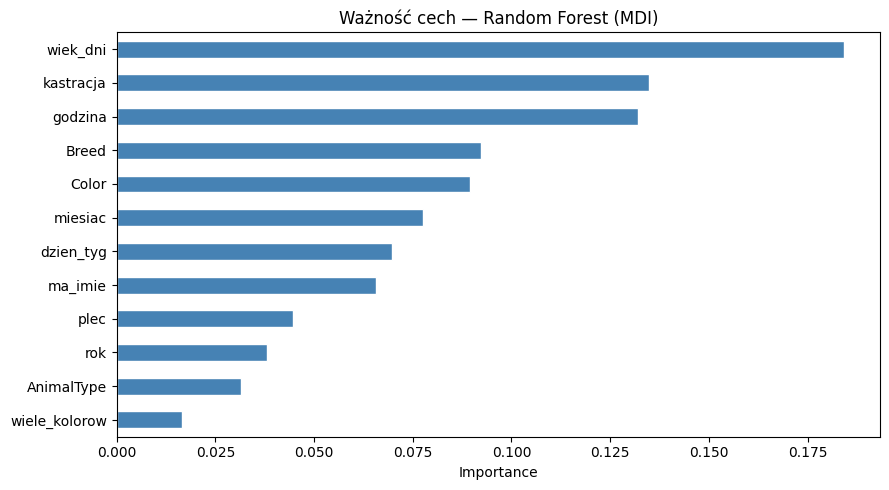

In [64]:
rf_model = best_rf.named_steps['model']
feature_names = (
    numeric_features +
    binary_features +
    categorical_features
)

importances = pd.Series(rf_model.feature_importances_, index=feature_names)
importances = importances.sort_values(ascending=False)

print("TOP 10 najważniejszych cech:")
print(importances.head(10).round(4))

fig, ax = plt.subplots(figsize=(9, 5))
importances.head(12).sort_values().plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Ważność cech — Random Forest (MDI)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

### 6.4 Redukcja wymiarowości — PCA

Liczba cech po preprocessingu: 14
Liczba komponentów PCA (95% wariancji): 2


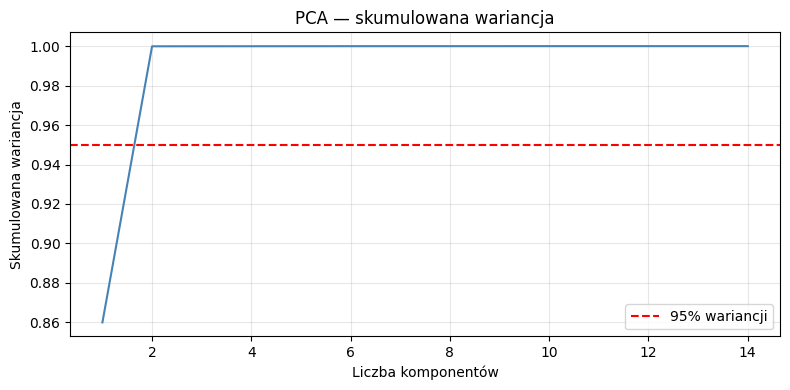

In [65]:
# Transformacja danych preprocessorem
X_train_transformed = best_rf.named_steps['preprocessing'].transform(X_train)
X_test_transformed  = best_rf.named_steps['preprocessing'].transform(X_test)

# PCA — ile komponentów potrzeba na 95% wariancji
pca_full = PCA(n_components=0.95, random_state=RANDOM_STATE)
pca_full.fit(X_train_transformed)

print(f"Liczba cech po preprocessingu: {X_train_transformed.shape[1]}")
print(f"Liczba komponentów PCA (95% wariancji): {pca_full.n_components_}")

# Wykres skumulowanej wariancji
pca_all = PCA(random_state=RANDOM_STATE)
pca_all.fit(X_train_transformed)
cum_var = np.cumsum(pca_all.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(cum_var)+1), cum_var, color='steelblue')
ax.axhline(0.95, color='red', linestyle='--', label='95% wariancji')
ax.set_xlabel('Liczba komponentów')
ax.set_ylabel('Skumulowana wariancja')
ax.set_title('PCA — skumulowana wariancja')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Model nienadzorowany — K-Means

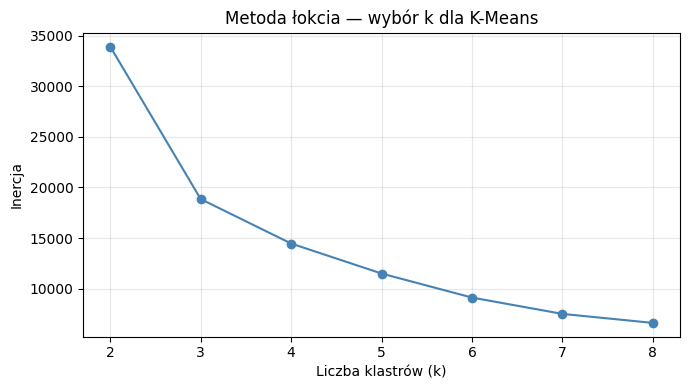

In [66]:
# K-Means na wiek + godzina
X_cluster = df[['wiek_dni', 'godzina']].copy()

# Imputacja braków przed klasteryzacją
X_cluster['wiek_dni']  = X_cluster['wiek_dni'].fillna(X_cluster['wiek_dni'].median())
X_cluster['godzina']   = X_cluster['godzina'].fillna(X_cluster['godzina'].median())

scaler_km = StandardScaler()
X_cluster_scaled = scaler_km.fit_transform(X_cluster)

# Metoda łokcia - wybór k
inertias = []
k_range  = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_cluster_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_range, inertias, marker='o', color='steelblue')
ax.set_xlabel('Liczba klastrów (k)')
ax.set_ylabel('Inercja')
ax.set_title('Metoda łokcia — wybór k dla K-Means')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

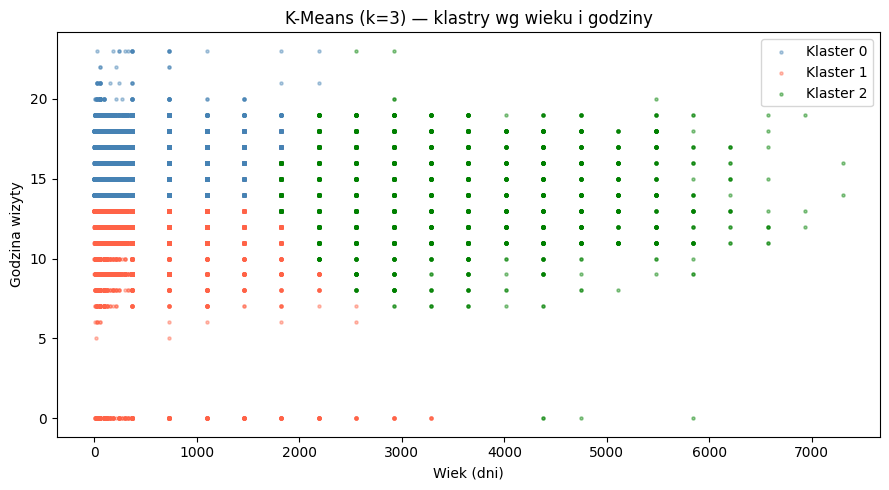


Charakterystyka klastrów:
         wiek_dni  godzina
klaster                   
0           410.9     16.5
1           469.7     10.7
2          3104.8     14.4

Najczęstszy wynik per klaster:
klaster
0           Adoption
1           Transfer
2    Return_to_owner
Name: OutcomeType, dtype: object


In [67]:
# K-Means z k=3
km3 = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
clusters = km3.fit_predict(X_cluster_scaled)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['steelblue', 'tomato', 'green']
for i, c in enumerate(colors):
    mask = clusters == i
    ax.scatter(X_cluster.loc[mask, 'wiek_dni'],
               X_cluster.loc[mask, 'godzina'],
               s=5, alpha=0.4, color=c, label=f'Klaster {i}')
ax.set_xlabel('Wiek (dni)')
ax.set_ylabel('Godzina wizyty')
ax.set_title('K-Means (k=3) — klastry wg wieku i godziny')
ax.legend()
plt.tight_layout()
plt.show()

# Średnie wartości per klaster
X_cluster['klaster'] = clusters
X_cluster['OutcomeType'] = y.values
print("\nCharakterystyka klastrów:")
print(X_cluster.groupby('klaster')[['wiek_dni', 'godzina']].mean().round(1))
print("\nNajczęstszy wynik per klaster:")
print(X_cluster.groupby('klaster')['OutcomeType'].agg(lambda x: x.value_counts().index[0]))

## 8. Podsumowanie

In [68]:
print("=" * 60)
print("PODSUMOWANIE WYNIKÓW")
print("=" * 60)

df_final = pd.DataFrame({
    'Model':              ['Baseline', 'Logistic Regression', 'Random Forest', 'k-NN'],
    'Accuracy (przed)':   [round(acc_baseline,4), round(acc_lr,4), round(acc_rf,4), round(acc_knn,4)],
    'Accuracy (po)':      [round(acc_baseline,4), round(acc_lr_tuned,4), round(acc_rf_tuned,4), round(acc_knn_tuned,4)],
    'Balanced Acc (po)':  [round(bal_baseline,4), round(bal_lr_tuned,4), round(bal_rf_tuned,4), round(bal_knn_tuned,4)],
})
print(df_final.to_string(index=False))

print("\nNajlepszy model: Random Forest")
print("Kluczowe cechy: wiek zwierzęcia, godzina wizyty, rasa, płeć/kastracja")
print("\nWnioski:")
print("- Zwierzęta z imieniem są częściej adoptowane")
print("- Wykastrowane zwierzęta mają lepsze wyniki niż niewykastrowane")
print("- Klasa Died jest najtrudniejsza do predykcji (bardzo mało obserwacji ~0.7%)")
print("- Random Forest najlepiej poradził sobie z niezbalansowanymi klasami")

PODSUMOWANIE WYNIKÓW
              Model  Accuracy (przed)  Accuracy (po)  Balanced Acc (po)
           Baseline            0.4029         0.4029             0.2000
Logistic Regression            0.5627         0.5627             0.3101
      Random Forest            0.6852         0.6906             0.4458
               k-NN            0.5436         0.5812             0.3455

Najlepszy model: Random Forest
Kluczowe cechy: wiek zwierzęcia, godzina wizyty, rasa, płeć/kastracja

Wnioski:
- Zwierzęta z imieniem są częściej adoptowane
- Wykastrowane zwierzęta mają lepsze wyniki niż niewykastrowane
- Klasa Died jest najtrudniejsza do predykcji (bardzo mało obserwacji ~0.7%)
- Random Forest najlepiej poradził sobie z niezbalansowanymi klasami
